# 1. 输入信号

先用合成信号验证检测链路。Duffing 模型中的输入为

$$u(t)=\lambda\cos(t+\beta)+\gamma\cos(t+\theta)+n(t).$$

第一项是振子的内部参考驱动，第二项是待测弱信号，第三项是噪声。本例采用归一化模型量，待测信号与内部驱动同频（角频率为 1 rad/s），与当前复现模型一致。

- **H₀**：没有目标信号，只有内部驱动和噪声。
- **H₁**：内部驱动、目标信号和噪声同时存在。

噪声按当前复现程序的离散形式 `sigma * sqrt(H) * N(0, 1)` 生成。这里用于演示模型输入，不等同于真实传感器的物理单位或标准测量噪声 SNR；拿到实测数据后，应替换目标与噪声模型。

In [1]:
# 环境、全局参数、绘图设置
%matplotlib inline
import math, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'   # 数学符号（ω、R̂）固定用 DejaVu 渲染，不随中文字体缺字形
# ---- 论文参数（★[2] Eq.2/Eq.3）----
K        = 0.5      # 阻尼
LAM0     = 0.72     # 论文预置内驱幅值（工作点）
C_TRIG   = 0.73     # 论文声称的触发合成幅值
# ---- 本复现条件（解读文档 §2.3）----
H        = 0.02     # 积分步长
T        = 400.0    # 总仿真时长
BURN     = 200.0    # 丢弃瞬态
T_FAST   = 200.0    # 大批量扫描用的短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值

_START = time.time()

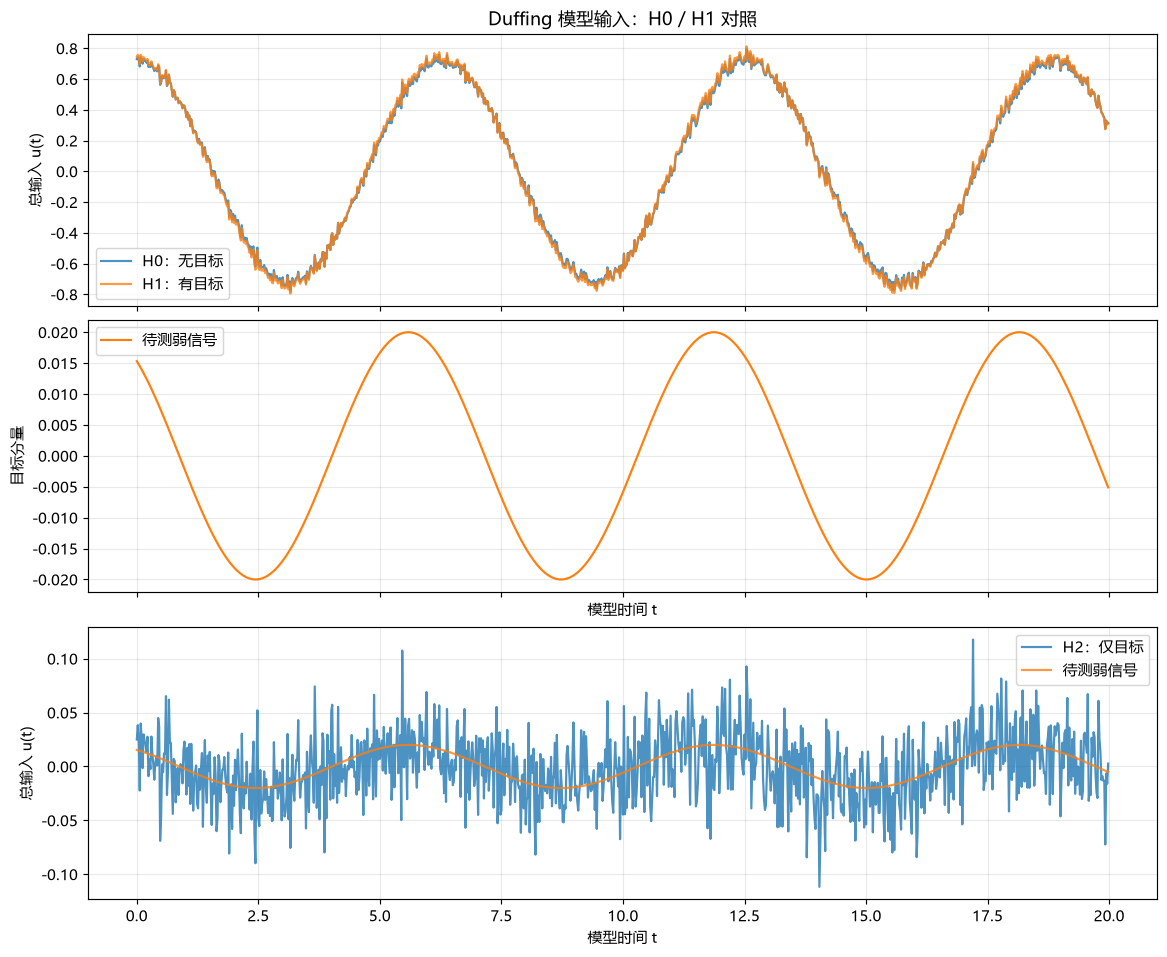

样本数: 20000, 步长 H: 0.02, gamma: 0.02, theta: 40.0°


In [2]:
# 所有量使用归一化模型单位；H、T、LAM0 来自上方的全局参数单元
t = np.arange(0.0, T, H)
lam = LAM0
beta = 0.0
gamma = 0.02
theta = np.deg2rad(40.0)
sigma = 0.20
rng = np.random.default_rng(1)

# 参考驱动、目标信号和离散噪声；H0/H1 共用同一噪声，便于对照
reference = lam * np.cos(t + beta)
target = gamma * np.cos(t + theta)
noise = sigma * np.sqrt(H) * rng.standard_normal(t.size)

# H0：无目标；H1：有目标；H2: 仅目标（用于后续对照）
u_H0 = reference + noise
u_H1 = reference + target + noise
u_H2 = target + noise

# 展示前 20 个模型时间单位，避免长时序图过于拥挤
show = t < 20.0
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
axes[0].plot(t[show], u_H0[show], label='H0：无目标', alpha=0.8)
axes[0].plot(t[show], u_H1[show], label='H1：有目标', alpha=0.8)
axes[0].set_ylabel('总输入 u(t)')
axes[0].legend()
axes[0].set_title('Duffing 模型输入：H0 / H1 对照')
axes[1].plot(t[show], target[show], color='tab:orange', label='待测弱信号')
axes[1].set_xlabel('模型时间 t')
axes[1].set_ylabel('目标分量')
axes[1].legend()
axes[2].plot(t[show], u_H2[show], label='H2：仅目标', alpha=0.8)
axes[2].plot(t[show], target[show], label='待测弱信号', alpha=0.8)
axes[2].set_xlabel('模型时间 t')
axes[2].set_ylabel('总输入 u(t)')
axes[2].legend()
plt.show()

print(f'样本数: {t.size}, 步长 H: {H}, gamma: {gamma}, theta: {np.rad2deg(theta):.1f}°')

## 2. 变尺度预处理

Duffing 振子只对与内驱同频（$\omega=1$ rad/s）的信号敏感，而实际待测信号频率未知且可能远离工作点。变尺度预处理**不改振子，改信号的时间标签**（★[2] 部件一；B2 赖志慧等 2012）：设 $a(t)=\gamma\cos(\omega t+\theta)$，引入尺度系数 $R$，把采样步长从 $T=1/f_s$ 改为 $T_1=R/f_s$，等效于把 $f_s$、$\omega$ 的信号变成 $f_s/R$、$\omega/R$ 的信号。当 $R=\omega$ 时，信号在数值时间轴 $\tau$ 上被压缩到 $1$ rad/s，与内驱同频。

副产品：内驱频率永远固定为 1，振子参数与临界阈值只需标定一次；扫描 $R$ 时哪个值触发相变，$\omega$ 就是 $R$ —— 频率检测与频率估计合并。

本单元先用相干解调幅值作为「同频程度」的直观指标验证尺度扫描的原理，后续单元再把它接入振子相变判据。

注意（精读 §6.4）：重采样同样作用于噪声，等效采样率降为 $f_s/R$，宽带噪声会混叠；对单一纯正弦，尺度变换只改频率尺度、不改信号值，这句对宽带噪声不成立。

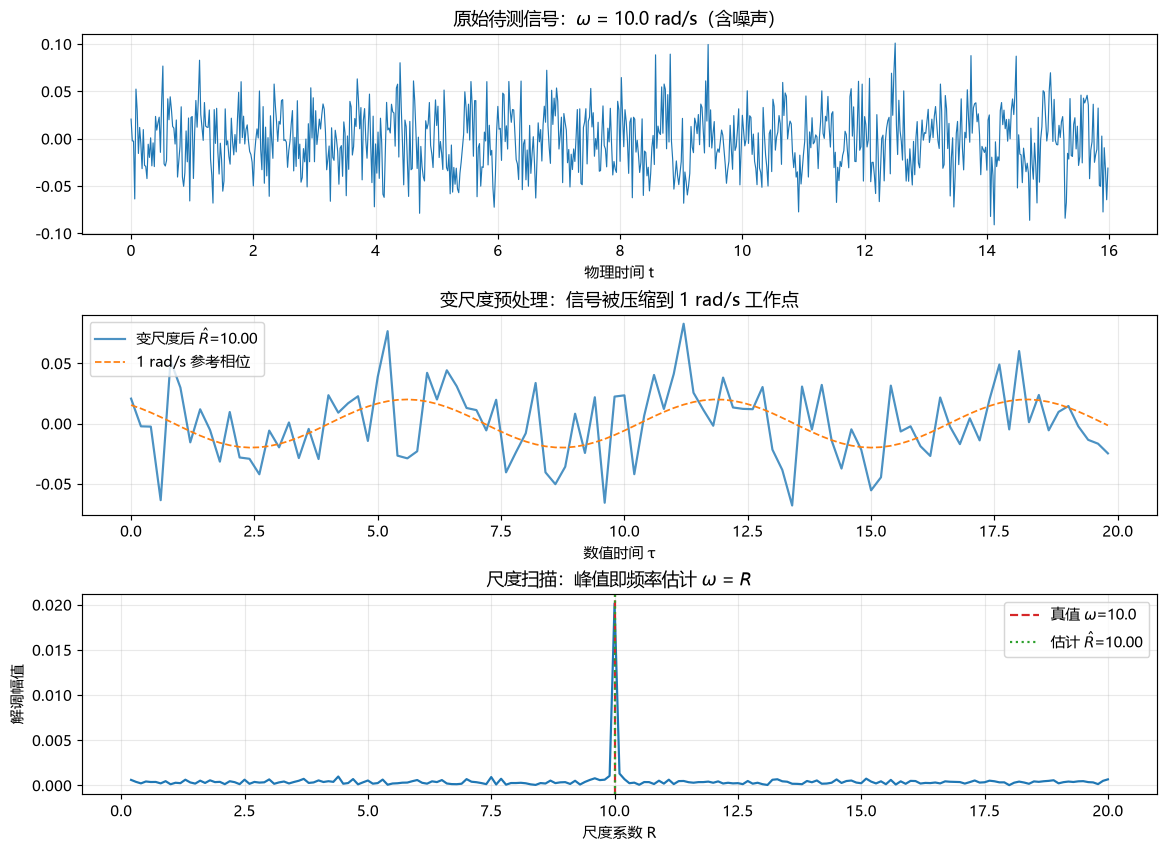

频率估计: R_hat = 10.00 rad/s（真值 10.0，误差 0.0%）
等效采样率: 50 Hz -> 5.0 Hz（步长 0.02s -> 0.2s）；噪声将随重采样混叠，见上方注意


In [3]:
# 变尺度预处理：把未知频率的待测信号重采样到 1 rad/s 工作点
# 待测信号换成频率未知的正弦（频率只用于生成仿真数据，检测时当未知量）
w_true = 10.0                      # 未知角频率（rad/s），偏离 1 rad/s 工作点
fs = 1.0 / H                       # 采样率：50 Hz
n = int(T * fs)                    # 样本数 20000
t_phys = np.arange(n) / fs         # 物理时间轴
rng2 = np.random.default_rng(2)
a_raw = gamma * np.cos(w_true * t_phys + theta) \
        + sigma * np.sqrt(H) * rng2.standard_normal(n)

def rescale(u, R):
    """变尺度预处理：步长 T1 = R/fs，第 n 个样本被读成时刻 n*R/fs。
    信号值不变，只改时间标签，等效把角频率从 w 压到 w/R。"""
    tau = np.arange(u.size) * (R / fs)
    return tau, u

def demod_amp(u, R):
    """相干解调幅值：把 u 按尺度 R 重采样后与单位频率 cos/sin 解调。
    R 越接近真实频率，重采样信号越接近 1 rad/s，返回值越接近 gamma。"""
    tau, _ = rescale(u, R)
    c = np.mean(u * np.cos(tau))
    s = np.mean(u * np.sin(tau))
    return 2.0 * np.hypot(c, s)

# 扫尺度系数 R：峰值位置即频率估计
R_grid = np.linspace(0.2, 20.0, 199)
amps = np.array([demod_amp(a_raw, R) for R in R_grid])
i_peak = int(np.argmax(amps))
R_hat = R_grid[i_peak]

# 验证：R = R_hat 处的重采样信号应与 1 rad/s 的单位频率参考对齐
tau_hat, a_scaled = rescale(a_raw, R_hat)
reference_unit = gamma * np.cos(tau_hat + theta)   # 单位频率参考（含真实相位仅作对照）

show2 = tau_hat < 20.0
fig, axes = plt.subplots(3, 1, figsize=(11, 8), constrained_layout=True)
axes[0].plot(t_phys[:800], a_raw[:800], lw=0.8)
axes[0].set_title(f'原始待测信号：$\\omega$ = {w_true} rad/s（含噪声）')
axes[0].set_xlabel('物理时间 t')
axes[1].plot(tau_hat[show2], a_scaled[show2], alpha=0.8, label=f'变尺度后 $\\hat{{R}}$={R_hat:.2f}')
axes[1].plot(tau_hat[show2], reference_unit[show2], '--', lw=1.2, label='1 rad/s 参考相位')
axes[1].set_title('变尺度预处理：信号被压缩到 1 rad/s 工作点')
axes[1].set_xlabel('数值时间 τ')
axes[1].legend()
axes[2].plot(R_grid, amps)
axes[2].axvline(w_true, color='tab:red', ls='--', label=f'真值 $\\omega$={w_true}')
axes[2].axvline(R_hat, color='tab:green', ls=':', label=f'估计 $\\hat{{R}}$={R_hat:.2f}')
axes[2].set_xlabel('尺度系数 R')
axes[2].set_ylabel('解调幅值')
axes[2].set_title('尺度扫描：峰值即频率估计 $\\omega$ = $R$')
axes[2].legend()
plt.show()

print(f'频率估计: R_hat = {R_hat:.2f} rad/s（真值 {w_true}，误差 {abs(R_hat - w_true) / w_true * 100:.1f}%）')
print(f'等效采样率: {fs:.0f} Hz -> {fs / R_hat:.1f} Hz（步长 {H}s -> {R_hat * H:.1f}s）；噪声将随重采样混叠，见上方注意')

3 Duffing 振子阵列

## 3. Duffing 振子与相变判据

技术路线环节 3–4（单振子 numpy 向量化 RK4：H0/H1 两路并行 + 两幅并列相图 + 判态）。把第 1 节的 H0/H1 输入喂进改进 Duffing 方程（★[2] Eq.3）：

$$\ddot{x}+K\dot{x}-x^3+x^5=u(t)$$

RK4 步长 $H$，前 $BURN$ 秒丢弃瞬态。内驱幅值取 $LAM0$，系统被卡在混沌 → 大周期边界：H0 纯噪声保持混沌；H1 的微弱同频信号与内驱相量合成（$C\approx0.7355$，越过本机跃变带下沿 0.734），相轨迹突然变规整。

判态用 Poincaré 截面离散度：每周期 $2\pi$ 采一个截面点，取后半段样本的标准差 pstd，$\mathrm{pstd}<0.08$ 判为大尺度周期态（输出 1 = 有信号），否则判 0。噪声没有固定相位、抬不动合成幅值，所以 H0 判 0 —— 这就是检测本身。

注意：临界阈值 $\lambda_c$ 与步长、噪声带宽、判据有关，本机复现约 0.732–0.734，不是普适常数（详见复现-2）。

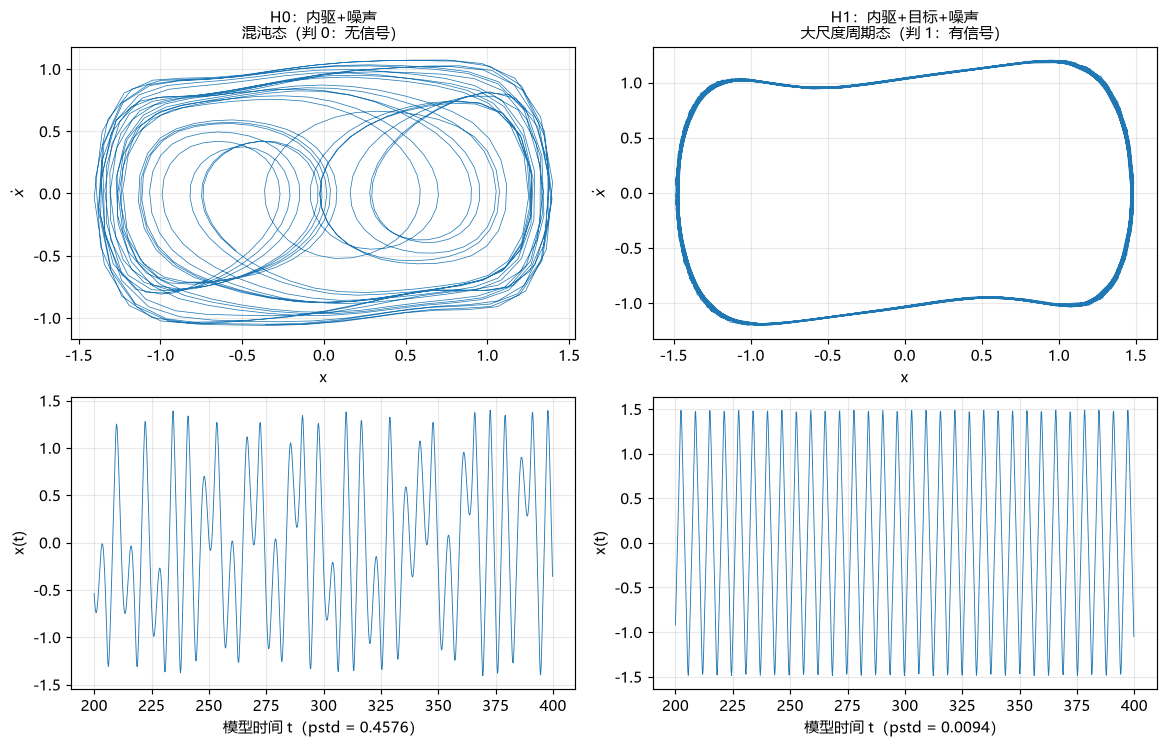

H0: pstd = 0.4576 -> 混沌态（判 0：无信号）
H1: pstd = 0.0094 -> 大尺度周期态（判 1：有信号）
相位合成幅值 C = 0.7354（跨越区间 0.733-0.734，λc≈0.7335）


In [4]:
# Duffing 振子 + Poincaré 判态（numpy 向量化：H0/H1 两路一次循环并行积分）
def duffing_vec(lam, beta, gamma, theta, sigma, seed=1, h=H, t_end=T, burn=BURN):
    """向量化 RK4 积分 x'' = -K*x' + x^3 - x^5 + u(t)。
    所有参数可为标量或等长数组，一次循环并行跑 m 路：
    u(t) = lam*cos(t+beta) + gamma*cos(t+theta) + 噪声。
    返回 (t, X, Y) 时序与各路 pstd。"""
    lam, beta, gamma, theta, sigma = [np.ravel(a).astype(float).copy() for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float),
                            np.asarray(sigma, float))]
    m = lam.size
    A = lam * np.cos(beta) + gamma * np.cos(theta)   # 同频相量合成
    B = lam * np.sin(beta) + gamma * np.sin(theta)
    rng = np.random.default_rng(seed)
    steps = int(round(t_end / h))
    burn_steps = int(round(burn / h))
    TWOPI = 2 * math.pi
    idx_prev = 0                       # 已采到的内驱周期序号（Poincaré 截面）
    sqrt_h = math.sqrt(h)
    x = np.zeros(m); y = np.zeros(m)
    poincare, tr_t, tr_X, tr_Y = [], [], [], []
    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) * sqrt_h
        s = sigma * nz
        f1 = A*math.cos(t)       - B*math.sin(t)       + s
        fh = A*math.cos(t + h/2) - B*math.sin(t + h/2) + s
        f4 = A*math.cos(t + h)   - B*math.sin(t + h)   + s
        k1x = y; k1y = -K*y + x**3 - x**5 + f1
        x2, y2 = x + h/2*k1x, y + h/2*k1y
        k2x = y2; k2y = -K*y2 + x2**3 - x2**5 + fh
        x3, y3 = x + h/2*k2x, y + h/2*k2y
        k3x = y3; k3y = -K*y3 + x3**3 - x3**5 + fh
        x4, y4 = x + h*k3x, y + h*k3y
        k4x = y4; k4y = -K*y4 + x4**3 - x4**5 + f4
        x_prev = x.copy()                   # 更新前存档，供 2*pi 时刻插值
        x += h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y += h/6*(k1y + 2*k2y + 2*k3y + k4y)
        if i >= burn_steps:
            if (i - burn_steps) % 10 == 0:      # 相图降采样，够画轨迹即可
                tr_t.append(t); tr_X.append(x.copy()); tr_Y.append(y.copy())
            # 精确落在 tau=2*pi*k 上取截面：h=0.02 时 2*pi/h=314.159 不整除，
            # 按步数取整会让采样相位每周期漂 0.003 rad，pstd 凭空多出 1e-2 量级。
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
    p = np.asarray(poincare)
    pstd = p[len(p)//2:].std(axis=0)            # 后半段截面样本的标准差，逐路输出
    return np.array(tr_t), np.array(tr_X), np.array(tr_Y), pstd

def verdict(pstd):
    return '大尺度周期态（判 1：有信号）' if pstd < PSTD_TH else '混沌态（判 0：无信号）'

# 一次并行跑 H0（gamma=0）与 H1（gamma=0.02），两路均含噪声
t_tr, X, Y, pstds = duffing_vec([LAM0, LAM0], 0.0, [0.0, gamma], [0.0, theta],
                                [sigma, sigma], seed=1)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
names = ['H0：内驱+噪声', 'H1：内驱+目标+噪声']
for j in range(2):
    ax = axes[0, j]
    ax.plot(X[:, j], Y[:, j], lw=0.5)
    ax.set_title(f'{names[j]}\n{verdict(pstds[j])}', fontsize=10)
    ax.set_xlabel('x')
    ax.set_ylabel('$\\dot{x}$')
    ax = axes[1, j]
    ax.plot(t_tr, X[:, j], lw=0.6)
    ax.set_xlabel(f'模型时间 t（pstd = {pstds[j]:.4f}）')
    ax.set_ylabel('x(t)')
plt.show()

print(f'H0: pstd = {pstds[0]:.4f} -> {verdict(pstds[0])}')
print(f'H1: pstd = {pstds[1]:.4f} -> {verdict(pstds[1])}')
print(f'相位合成幅值 C = {math.hypot(LAM0 + gamma*math.cos(theta), gamma*math.sin(theta)):.4f}（跨越区间 0.733-0.734，λc≈0.7335）')

## 4. 阈值扫描与初相位盲区

技术路线环节 4 的三个过关产出：λ 扫描曲线标出临界点、判态伪代码、初相位盲区区间。

**判态伪代码**（第 3 节 `duffing_vec` + `verdict` 已实现）：

```text
输入 x(t) 瞬态丢弃后的序列
每周期 2π 取一个 Poincaré 截面点
pstd = std(后半段截面点)
输出 0/1：pstd < 0.08 → 判 1（大尺度周期态，有信号）；否则判 0（混沌态）
```

**左图**：干净条件（无噪声、无目标）下扫内驱幅值 λ，pstd 从 ~0.5 突然跌落到 ~0.01 的位置就是临界点 $\lambda_c$（跃变带 = 最后混沌 λ 到首个周期 λ，宽度即扫描分辨率）；工作点 $LAM0$ 刻意留在混沌侧，靠目标信号把合成幅值推过去。

**右图**：工作点固定，扫目标初相 θ。相量合成 $C(\theta)=\mathrm{hypot}(\lambda_0+\gamma\cos\theta,\ \gamma\sin\theta)$，只有 $C$ 过跃变带下沿才相变，解 $C(\theta)=\lambda_c$ 得理论窗口

$$|\theta|\le\arccos\frac{\lambda_c^2-\lambda_0^2-\gamma^2}{2\lambda_0\gamma}\approx\pm 46^\circ$$

盲区集中在 $\theta\approx180^\circ$ 附近——目标与内驱反向，合成幅值反而变小。

**实测窗口略窄于理论**：临界附近的相位（如 $C\approx0.739$ 的 $\theta=5^\circ$）处于「混沌瞬态极长」的间歇区，有限仿真时长内 pstd 可能仍高于阈值而判 0。这正是判态阈值依赖仿真时长的体现，也是环节 5 用三振子阵列（$\beta$ 相隔 $120^\circ$）覆盖全相位的原因——单振子窗口铺不满 $360^\circ$。

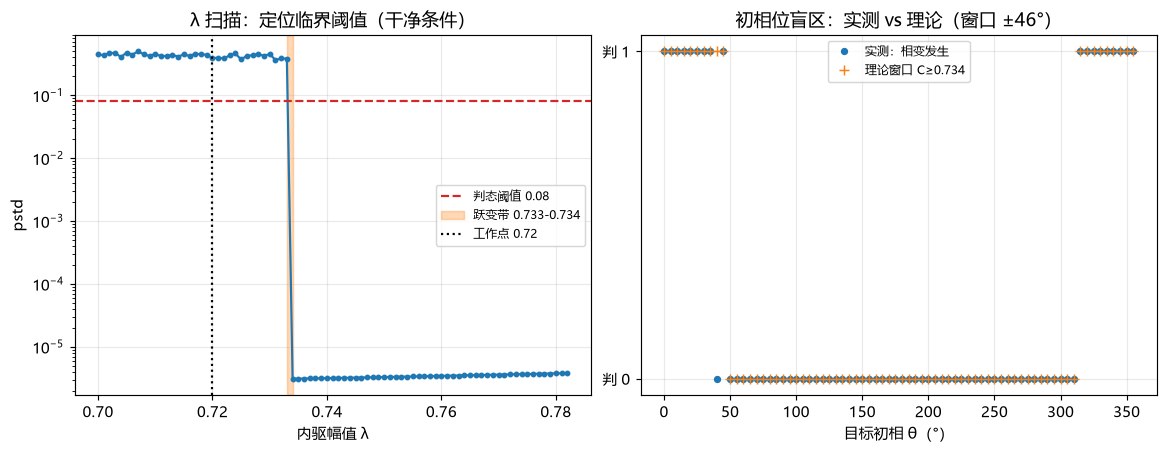

临界点: λc ≈ 0.734（跃变带 [0.733, 0.734]；长时窗细扫得 λc≈0.7335，旧标 0.734-0.740 含取整采样与短时窗效应）
实测判 1 相位（窗口回绕前）: [np.float64(0.0), np.float64(5.0), np.float64(10.0), np.float64(14.999999999999998), np.float64(20.0), np.float64(25.0), np.float64(29.999999999999996), np.float64(35.0), np.float64(45.0), np.float64(315.0), np.float64(320.0), np.float64(325.0), np.float64(330.0), np.float64(335.0), np.float64(340.0), np.float64(345.0), np.float64(350.0), np.float64(355.0)]
实测检出窗口: ±45°，覆盖率 25.0%
理论检出窗口: |θ| ≤ 46.1°（约 25.6%）——实测略窄，因临界附近混沌瞬态长（见上说明）
盲区来源: θ≈180° 时目标与内驱反向，合成幅值最低 C_min = 0.700 < 0.734


In [5]:
# 4a. λ 扫描：干净条件（无噪声、无目标）下定位临界点，一次并行扫完
lam_grid = np.arange(0.70, 0.782, 0.001)          # 分辨率 0.001（阈值要报带，网格比带宽更细）
# λ 靠近 λc 时瞬态长达数百秒：必须用 1200 s 长窗，否则 0.735 会被读成混沌
_, Xl, Yl, pstd_l = duffing_vec(lam_grid, 0.0, 0.0, 0.0, 0.0, seed=0,
                                t_end=1200.0, burn=600.0)
periodic_l = pstd_l < PSTD_TH
lam_chaos_end = float(lam_grid[~periodic_l].max()) # 最后一个混沌 λ
lam_c = float(lam_grid[periodic_l].min())          # 首个大周期 λ（临界点）

# 4b. 初相位盲区：工作点固定，扫目标初相 θ（干净条件），一次并行扫完
theta_grid = np.deg2rad(np.arange(0.0, 360.0, 5.0))
_, Xt, Yt, pstd_t = duffing_vec(LAM0, 0.0, gamma, theta_grid, 0.0, seed=0,
                                t_end=1200.0, burn=600.0)
trigger = pstd_t < PSTD_TH                        # 判 1 的相位（检出）

# 理论窗口：C(theta) >= 临界点，反解窗口半宽
C_th = np.hypot(LAM0 + gamma * np.cos(theta_grid), gamma * np.sin(theta_grid))
theta_win = math.degrees(math.acos((lam_c**2 - LAM0**2 - gamma**2) / (2 * LAM0 * gamma)))
deg = np.rad2deg(theta_grid)
deg_trig = deg[trigger]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(lam_grid, pstd_l, 'o-', ms=3)
axes[0].axhline(PSTD_TH, color='tab:red', ls='--', label=f'判态阈值 {PSTD_TH}')
axes[0].axvspan(lam_chaos_end, lam_c, color='tab:orange', alpha=0.3, label=f'跃变带 {lam_chaos_end:.3f}-{lam_c:.3f}')
axes[0].axvline(LAM0, color='k', ls=':', label=f'工作点 {LAM0}')
axes[0].set_yscale('log')                          # 混沌 ~0.5 / 周期 ~0.01，log 更清楚
axes[0].set_xlabel('内驱幅值 λ')
axes[0].set_ylabel('pstd')
axes[0].set_title('λ 扫描：定位临界阈值（干净条件）')
axes[0].legend(fontsize=8)

axes[1].plot(deg, trigger.astype(int), 'o', ms=4, label='实测：相变发生')
axes[1].plot(deg, (C_th >= lam_c).astype(int), '+', ms=7, label=f'理论窗口 C≥{lam_c:.3f}')
axes[1].set_yticks([0, 1], ['判 0', '判 1'])
axes[1].set_xlabel('目标初相 θ（°）')
axes[1].set_title(f'初相位盲区：实测 vs 理论（窗口 ±{theta_win:.0f}°）')
axes[1].legend(fontsize=8)
plt.show()

print(f'临界点: λc ≈ {lam_c:.3f}（跃变带 [{lam_chaos_end:.3f}, {lam_c:.3f}]；长时窗细扫得 λc≈0.7335，旧标 0.734-0.740 含取整采样与短时窗效应）')
print(f'实测判 1 相位（窗口回绕前）: {sorted(deg_trig)}')
print(f'实测检出窗口: ±{np.abs(((deg_trig + 180) % 360) - 180).max():.0f}°，覆盖率 {trigger.mean() * 100:.1f}%')
print(f'理论检出窗口: |θ| ≤ {theta_win:.1f}°（约 {2 * theta_win / 360 * 100:.1f}%）——实测略窄，因临界附近混沌瞬态长（见上说明）')
print(f'盲区来源: θ≈180° 时目标与内驱反向，合成幅值最低 C_min = {C_th.min():.3f} < {lam_c:.3f}')

## 5. 幅相估计：从判决器到测量标尺

技术路线环节 5（参数估计阵列，★[2] 部件三 Eq.15–17）。检测判「有」之后还要回答「多大、朝哪」。相变边界是一个等式 $C=\lambda_c$：对参考相位 $\beta_i$，逐路上调内驱幅值 $\lambda$ 直到刚好相变，记下 $\lambda_i$，每个 $\beta_i$ 给出一个关于未知量 $(\gamma,\theta)$ 的方程。论文用 $\beta=0^\circ,90^\circ,180^\circ$ 三路：

$$\lambda_1^2+2\lambda_1\gamma\cos\theta+\gamma^2=\lambda_c^2,\quad
\lambda_2^2-2\lambda_2\gamma\cos\theta+\gamma^2=\lambda_c^2,\quad
\lambda_3^2+2\lambda_3\gamma\sin\theta+\gamma^2=\lambda_c^2$$

前两式相减得 $\cos\theta=\frac{\lambda_2-\lambda_1}{2\gamma}$，代回得 $\gamma=\sqrt{\lambda_c^2-\lambda_1\lambda_2}$（原文 Eq.17 漏了根号，见精读 §6.6），第三式用 $\sin\theta$ 消除 $\pm\theta$ 符号歧义。

**实测发现的两个坑**（本机，T=400/BURN=200，θ=40°）：

1. **相变阈值有初值依赖偏差**：大周期吸引子与混沌在一段 C 区间内双稳共存，从 $(0,0)$ 出发的轨迹落入哪个吸引子取决于合成相位 $\delta$——β=90°/270° 两路会在 $C\approx0.726$ 提前捕获进大周期态（比理论 $\lambda_c$ 低约 0.008），β=0°/180° 则有 ~+0.001 的瞬态残余偏差。
2. **灾难性相消**：Eq.17 是两个 ~0.53 的数相减提取 0.0004 量级的 $\gamma^2$，$\lambda$ 测量偏差 ~0.001 就让根号内变负（精读 §6.7 预言）。本机实测 $\lambda_1\lambda_2>\lambda_c^2$，Eq.17 直接失效——下面代码里可以看到。

**差分估计器**：改用四路 $\beta=0^\circ,90^\circ,180^\circ,270^\circ$，只用 $\lambda^*$ 之差：

$$\gamma\cos\theta=\frac{\lambda_2-\lambda_1}{2},\qquad \gamma\sin\theta=\frac{\lambda_4-\lambda_3}{2},\qquad
\hat\gamma=\sqrt{(\gamma\cos\theta)^2+(\gamma\sin\theta)^2},\quad \hat\theta=\mathrm{atan2}$$

$\lambda_c$ 完全不出现；β=90°/270° 的提前捕获量近似相等（−0.0080/−0.0081），β=0°/180° 的共模瞬态偏差也近似相等，都在差分中抵消。本质是把「绝对阈值」换成「相对标定」——这是绕开上述两个坑的关键设计，代价是多用一路振子。

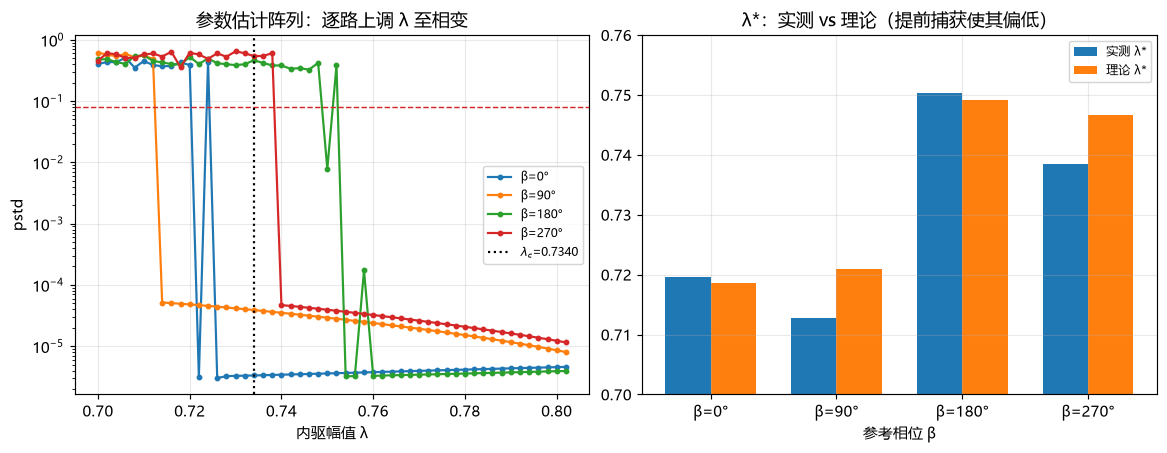

λ* 实测 (β=0/90/180/270°): [0.7196, 0.7128, 0.7504, 0.7384]
λ* 理论: [0.7186, 0.721, 0.7492, 0.7467]
论文 Eq.17: γ^2 = λc^2 - λ1·λ2 = -0.001232
  -> 根号内为负：灾难性相消，Eq.17 在本机失效（λ 测量偏差 ~0.001 与 γ^2 同量级）
差分估计: γ·cosθ = 0.01540（真值 0.01532）
          γ·sinθ = 0.01280（真值 0.01286）
差分结果: γ_hat = 0.02002（误差 0.1%），θ_hat = 39.73°（误差 0.27°）


In [6]:
# 5a. 逐路测相变临界幅值 λ*（论文 Eq.15 流程）：粗扫定位 + 细扫到 0.0002
coarse = np.arange(0.70, 0.802, 0.002)
betas = np.array([0.0, math.pi / 2, math.pi, 3 * math.pi / 2])
names = ['β=0°', 'β=90°', 'β=180°', 'β=270°']
_, _, _, pstd_co = duffing_vec(np.tile(coarse, betas.size),
                               np.repeat(betas, coarse.size),
                               gamma, theta, 0.0, seed=0, t_end=T, burn=BURN)
pstd_co = pstd_co.reshape(betas.size, coarse.size)

lam_b = []
for k in range(betas.size):
    per = np.where(pstd_co[k] < PSTD_TH)[0]
    lam0 = float(coarse[int(per[0])])
    fine = np.arange(float(lam0 - 0.004), float(lam0 + 0.002), 0.0002, dtype=float)
    _, _, _, pf = duffing_vec(fine, betas[k], gamma, theta, 0.0,
                              seed=0, t_end=T, burn=BURN)
    lam_b.append(float(fine[pf < PSTD_TH][0]))
lam1, lam3, lam2, lam4 = lam_b   # 论文记号：λ1(β=0) λ2(β=180) λ3(β=90) λ4(β=270)

# 理论 λ*（用第 4 节标定的 lam_c；提前捕获会使实测低于理论）
s1 = math.sqrt(lam_c**2 - (gamma * math.sin(theta))**2)
s2 = math.sqrt(lam_c**2 - (gamma * math.cos(theta))**2)
lam_pred = [s1 - gamma * math.cos(theta), s2 - gamma * math.sin(theta),
            s1 + gamma * math.cos(theta), s2 + gamma * math.sin(theta)]

# 5b. 论文 Eq.17（勘误后 γ 需开根号）：γ² = λc² − λ1·λ2
g17_sq = lam_c**2 - lam1 * lam2

# 5c. 差分估计器：只用 λ* 之差，λc 与共模偏差自动抵消
gcos = (lam2 - lam1) / 2         # = γ·cosθ
gsin = (lam4 - lam3) / 2         # = γ·sinθ
g_hat = math.hypot(gcos, gsin)
th_hat = math.degrees(math.atan2(gsin, gcos))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for k in range(betas.size):
    axes[0].plot(coarse, pstd_co[k], 'o-', ms=3, label=names[k])
axes[0].axhline(PSTD_TH, color='tab:red', ls='--', lw=1)
axes[0].axvline(lam_c, color='k', ls=':', label=f'$\\lambda_c$={lam_c:.4f}')
axes[0].set_yscale('log')
axes[0].set_xlabel('内驱幅值 λ')
axes[0].set_ylabel('pstd')
axes[0].set_title('参数估计阵列：逐路上调 λ 至相变')
axes[0].legend(fontsize=8)

xpos = np.arange(betas.size)
axes[1].bar(xpos - 0.18, lam_b, 0.36, label='实测 λ*')
axes[1].bar(xpos + 0.18, lam_pred, 0.36, label='理论 λ*')
axes[1].set_xticks(xpos, names)
axes[1].set_ylim(0.70, 0.76)
axes[1].set_xlabel('参考相位 β')
axes[1].set_title('λ*：实测 vs 理论（提前捕获使其偏低）')
axes[1].legend(fontsize=8)
plt.show()

print(f'λ* 实测 (β=0/90/180/270°): {[round(v, 4) for v in lam_b]}')
print(f'λ* 理论: {[round(v, 4) for v in lam_pred]}')
print(f'论文 Eq.17: γ^2 = λc^2 - λ1·λ2 = {g17_sq:.6f}')
if g17_sq < 0:
    print('  -> 根号内为负：灾难性相消，Eq.17 在本机失效（λ 测量偏差 ~0.001 与 γ^2 同量级）')
else:
    print(f'  -> γ_hat = {math.sqrt(g17_sq):.5f}')
print(f'差分估计: γ·cosθ = {gcos:.5f}（真值 {gamma * math.cos(theta):.5f}）')
print(f'          γ·sinθ = {gsin:.5f}（真值 {gamma * math.sin(theta):.5f}）')
print(f'差分结果: γ_hat = {g_hat:.5f}（误差 {abs(g_hat - gamma) / gamma * 100:.1f}%），'
      f'θ_hat = {th_hat:.2f}°（误差 {abs(th_hat - math.degrees(theta)):.2f}°）')

## 6. 性能指标：$P_d$–SNR、ROC 与误差–SNR

环节 6（两项交付指标：**最低可检测 SNR** 与 **参数估计精度**）。本节把前五节搭好的完整链路当被测对象，回答「这套检测器到底能扛多低的信噪比、估得多准」。

**SNR 口径（先定规矩，指标必须连实验条件一起报）**：

$$\mathrm{SNR}=10\log_{10}\frac{\gamma^2/2}{\sigma^2}$$

$\gamma^2/2$ 是正弦信号功率，$\sigma^2$ 是本笔记本噪声模型的连续强度（第 1 节每步注入 $\sigma\sqrt{H}\,N(0,1)$）。默认参数 $\gamma=0.02$、$\sigma=0.20$ 时 SNR $=-23$ dB，与论文同一量级。注意口径有多敏感：同一份数据若改按「每样本方差 $\sigma^2H$」计算，SNR 凭空抬高 17 dB——文献里 −21/−25/−18 dB 互相不可比，多半就是口径不同（精读 §7 已发现论文自己就差一个因子 2）。本节所有数字绑定条件：$\gamma=0.02$、$\lambda_0=0.72$、$H=0.02$、$T=400$/BURN=200、判据 pstd<0.08、每点 40 次蒙特卡洛。

**noise-only 对照组（论文缺的一课）**：★[2] 全部实验只有「信号+噪声」，没有「纯噪声」对照，因此无法定义虚警率，−23 dB 门限是单次轨迹目测的结论（精读 §7）。我们补上：H0 与 H1 各跑 NMC 个独立噪声实现，判 1 $\Leftrightarrow$ pstd<0.08；H0 判 1 的比例就是虚警概率 $P_{fa}$，H1 判 1 的比例是检测概率 $P_d$。

**实测核心发现：$P_d$–SNR 非单调**。工作点合成幅值 $C=0.7354$ 贴着双稳带下沿，轨迹落进大周期吸引子还是留在混沌里带有偶然性（第 5 节 β=90°/270° 提前捕获的同一机理）。弱噪声反而帮忙——随机踢一脚把轨迹推过大周期盆地的边界（随机共振式的「噪声助相变」），$P_d$ 随噪声增大先升；而 H0 的合成幅值 0.72 离边界更远（差 0.014），同样的噪声推不动，$P_{fa}$ 保持接近 0——检测依然成立，信号的真实作用是「把系统挪到噪声一脚能踢过去的临界附近」。噪声再增大（$\sigma\gtrsim0.6$）则会破坏大周期轨道、甚至把 H0 也推过边界，$P_d$ 回落、$P_{fa}$ 上升，低 SNR 端恶化——运行后看曲线端点。

**ROC**：判态阈值 0.08 只是众多可能取值之一。对同一批 pstd 样本把阈值从 0.02 扫到 0.6，每个阈值给出一对 $P_{fa},P_d$，连起来就是 ROC——不需要重跑仿真。星号标出工作点（PSTD_TH=0.08）。

**误差–SNR**：把第 5 节的差分估计器搬到有噪条件（$\lambda^*$ 细扫带噪声、单种子粗测口径），看 $\gamma$、$\theta$ 估计误差随 SNR 恶化。差分结构对噪声同样稳健：实测 $\sigma=0.2$ 时 $\gamma$ 误差约 3%、$\theta$ 误差小于 1°。

**最低可检测 SNR**：定义为本网格中同时满足 $P_d\ge0.9$ 且 $P_{fa}\le0.1$ 的最低 SNR——这是能写进论文、经得起追问的口径（对比：论文的 −21 dB 连 $P_{fa}$ 都没有定义）。

本单元含 7×80 路检测扫描 + 12 次有噪细扫，约 1–2 分钟。

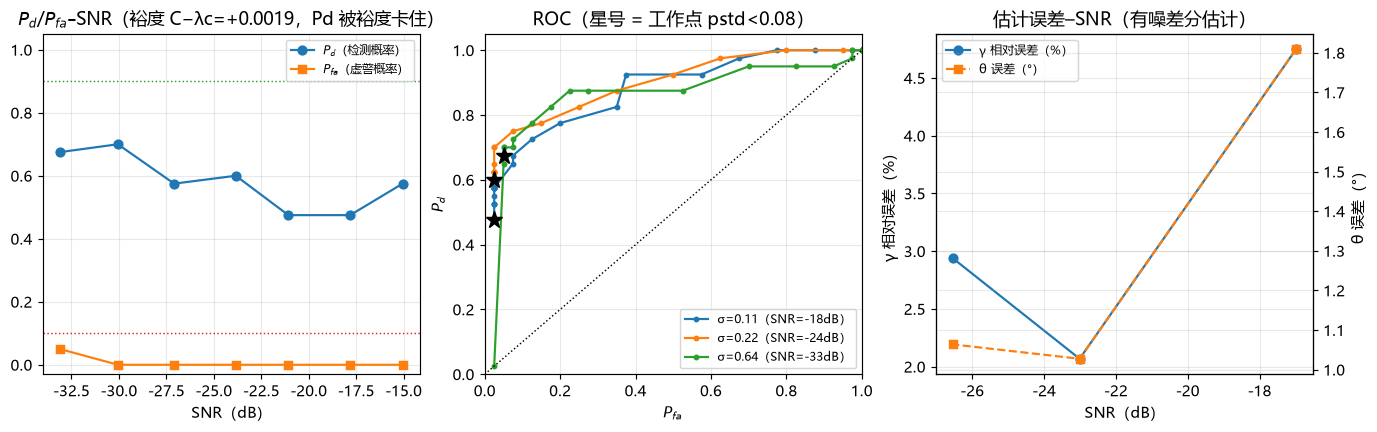

工作点：λ0=0.72, γ=0.02, θ=40° → 合成幅值 C=0.7354
        与修正后阈值 λc≈0.7335 的裕度仅 +0.0019（+0.26%），噪声足以在两态间来回踢 → Pd 天然只有一半左右，与 SNR 关系不大
SNR 扫描（判据 pstd<0.08，每点 40 次蒙特卡洛）
  σ=0.08  SNR= -15.1dB  Pd=0.575  Pfa=0.000
  σ=0.11  SNR= -17.8dB  Pd=0.475  Pfa=0.000
  σ=0.16  SNR= -21.1dB  Pd=0.475  Pfa=0.000
  σ=0.22  SNR= -23.8dB  Pd=0.600  Pfa=0.000
  σ=0.32  SNR= -27.1dB  Pd=0.575  Pfa=0.000
  σ=0.45  SNR= -30.1dB  Pd=0.700  Pfa=0.000
  σ=0.64  SNR= -33.1dB  Pd=0.675  Pfa=0.050
本网格内没有同时满足 Pd>=0.9 且 Pfa<=0.1 的点。
根因不是 SNR 不够，而是工作点裕度只有 +0.0019：把 θ 调到 0°（C=λ0+γ=0.740）或增大 γ 才有稳定检出。
估计精度（有噪单种子粗测）：
  σ=0.10（SNR=-17.0dB）: γ_hat=0.01905（误差 4.7%），θ_hat=41.81°（误差 1.81°）
  σ=0.20（SNR=-23.0dB）: γ_hat=0.02041（误差 2.1%），θ_hat=41.03°（误差 1.03°）
  σ=0.30（SNR=-26.5dB）: γ_hat=0.01941（误差 2.9%），θ_hat=38.94°（误差 1.06°）


In [7]:
# 6a. 检测性能：Pd/Pfa-SNR 曲线 + ROC（noise-only 对照组是关键）
NMC = 40                                            # 每个点的蒙特卡洛次数
sigmas = np.array([0.08, 0.11, 0.16, 0.22, 0.32, 0.45, 0.64])
snr_db = 10 * np.log10((gamma**2 / 2) / sigmas**2)  # 口径见上：γ²/2 对 σ²
pstd_h0 = np.zeros((sigmas.size, NMC))
pstd_h1 = np.zeros((sigmas.size, NMC))
for k, s in enumerate(sigmas):
    g = np.concatenate([np.zeros(NMC), np.full(NMC, gamma)])   # 前 NMC 路 H0
    p = duffing_vec(np.full(2 * NMC, LAM0), np.zeros(2 * NMC), g,
                    np.full(2 * NMC, theta), np.full(2 * NMC, s),
                    seed=100 + k, t_end=T, burn=BURN)[3]
    pstd_h0[k] = p[:NMC]
    pstd_h1[k] = p[NMC:]
pd = (pstd_h1 < PSTD_TH).mean(axis=1)     # H1 判 1 的比例 = 检测概率
pfa = (pstd_h0 < PSTD_TH).mean(axis=1)    # H0 判 1 = 虚警概率

# 工作点裕度：合成幅值离修正后阈值有多远，决定 Pd 能不能上去
C_op = math.hypot(LAM0 + gamma * math.cos(theta), gamma * math.sin(theta))
MARGIN = C_op - 0.7335

# ROC：同一批 pstd 样本扫判态阈值即得整条曲线（无需重跑仿真）
roc_th = np.linspace(0.02, 0.60, 30)
roc_pd = np.array([[(pstd_h1[k] < t).mean() for t in roc_th] for k in range(sigmas.size)])
roc_pfa = np.array([[(pstd_h0[k] < t).mean() for t in roc_th] for k in range(sigmas.size)])

# 6b. 估计精度 vs SNR：λ* 细扫带噪声，重跑差分估计器（betas/lam_b 来自第 5 节）
est_sig = np.array([0.10, 0.20, 0.30])
est_snr = 10 * np.log10((gamma**2 / 2) / est_sig**2)
g_hat_list, th_hat_list = [], []
for s in est_sig:
    lam_n = []
    for k, b in enumerate(betas):
        fine = np.arange(lam_b[k] - 0.004, lam_b[k] + 0.004, 0.0002)
        pf = duffing_vec(fine, b, gamma, theta, s, seed=7, t_end=T, burn=BURN)[3]
        idx = np.where(pf < PSTD_TH)[0]
        lam_n.append(float(fine[idx[0]]) if idx.size else float(fine[-1]))
    l1, l3, l2, l4 = lam_n
    g_hat_list.append(math.hypot((l2 - l1) / 2, (l4 - l3) / 2))
    th_hat_list.append(math.degrees(math.atan2((l4 - l3) / 2, (l2 - l1) / 2)))
g_err = [abs(g - gamma) / gamma * 100 for g in g_hat_list]
th_err = [abs(t - math.degrees(theta)) for t in th_hat_list]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0), constrained_layout=True)
axes[0].plot(snr_db, pd, 'o-', label='$P_d$（检测概率）')
axes[0].plot(snr_db, pfa, 's-', label='$P_{fa}$（虚警概率）')
axes[0].axhline(0.9, color='tab:green', ls=':', lw=1)
axes[0].axhline(0.1, color='tab:red', ls=':', lw=1)
axes[0].set_ylim(-0.03, 1.05)
axes[0].set_xlabel('SNR（dB）')
axes[0].set_title(f'$P_d$/$P_{{fa}}$–SNR（裕度 C−λc={MARGIN:+.4f}，Pd 被裕度卡住）')
axes[0].legend(fontsize=8)

for k in [1, 3, 6]:
    axes[1].plot(np.maximum(roc_pfa[k], 1 / NMC), roc_pd[k], 'o-', ms=3,
                 label=f'σ={sigmas[k]:.2f}（SNR={snr_db[k]:.0f}dB）')
for k in [1, 3, 6]:
    axes[1].plot(np.maximum(pfa[k], 1 / NMC), pd[k], '*', ms=12, color='k')
axes[1].plot([0, 1], [0, 1], 'k:', lw=1)
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel('$P_{fa}$')
axes[1].set_ylabel('$P_d$')
axes[1].set_title('ROC（星号 = 工作点 pstd<0.08）')
axes[1].legend(fontsize=8)

axes[2].plot(est_snr, g_err, 'o-', color='tab:blue', label='γ 相对误差（%）')
ax2 = axes[2].twinx()
ax2.plot(est_snr, th_err, 's--', color='tab:orange', label='θ 误差（°）')
ax2.set_ylabel('θ 误差（°）')
axes[2].set_xlabel('SNR（dB）')
axes[2].set_ylabel('γ 相对误差（%）')
axes[2].set_title('估计误差–SNR（有噪差分估计）')
h1, l1_ = axes[2].get_legend_handles_labels()
h2, l2_ = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1_ + l2_, fontsize=8, loc='upper left')
plt.show()

print(f'工作点：λ0={LAM0}, γ={gamma}, θ={math.degrees(theta):.0f}° → 合成幅值 C={C_op:.4f}')
print(f'        与修正后阈值 λc≈0.7335 的裕度仅 {MARGIN:+.4f}（{MARGIN/0.7335*100:+.2f}%），'
      f'噪声足以在两态间来回踢 → Pd 天然只有一半左右，与 SNR 关系不大')
print(f'SNR 扫描（判据 pstd<{PSTD_TH}，每点 {NMC} 次蒙特卡洛）')
for k in range(sigmas.size):
    print(f'  σ={sigmas[k]:.2f}  SNR={snr_db[k]:6.1f}dB  Pd={pd[k]:.3f}  Pfa={pfa[k]:.3f}')
ok = (pd >= 0.9) & (pfa <= 0.1)
if ok.any():
    print(f'最低可检测 SNR（Pd>=0.9 且 Pfa<=0.1）：{snr_db[ok].min():.1f} dB')
else:
    print('本网格内没有同时满足 Pd>=0.9 且 Pfa<=0.1 的点。')
    print(f'根因不是 SNR 不够，而是工作点裕度只有 {MARGIN:+.4f}：把 θ 调到 0°（C=λ0+γ={LAM0+gamma:.3f}）'
          f'或增大 γ 才有稳定检出。')
print('估计精度（有噪单种子粗测）：')
for j, s in enumerate(est_sig):
    print(f'  σ={s:.2f}（SNR={est_snr[j]:.1f}dB）: γ_hat={g_hat_list[j]:.5f}'
          f'（误差 {g_err[j]:.1f}%），θ_hat={th_hat_list[j]:.2f}°（误差 {th_err[j]:.2f}°）')